<a href="https://colab.research.google.com/github/jeyohub/flutter_another_sample/blob/master/Silhouette.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler




In [118]:
from google.colab import drive
drive.mount("/content/drive")

directory = "/content/drive/MyDrive/datasets/live.csu"



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [119]:
import os
import pandas as pd
import numpy as np

directory = "/content/drive/MyDrive/datasets/live.csv"

# Fallback check and automated sample creation so you can test immediately
if not os.path.exists(directory) and not os.path.exists("live.csv"):
    print("[INFO] 'live.csv' not found. Generating a mock dataset to allow execution...")
    np.random.seed(42)
    mock_data = {
        'status_id': [f"id_{i}" for i in range(100)],
        'status_published': [pd.Timestamp('2023-01-01') + pd.Timedelta(days=i) for i in range(100)],
        'status_type': np.random.choice(['photo', 'video', 'status', 'link'], size=100),
        'num_reactions': np.random.randint(0, 1000, size=100),
        'num_comments': np.random.randint(0, 500, size=100),
        'num_shares': np.random.randint(0, 300, size=100),
        'num_likes': np.random.randint(0, 800, size=100),
        'Column1': [np.nan]*100,
        'Column2': [np.nan]*100
    }
    df_mock = pd.DataFrame(mock_data)
    df_mock.to_csv("live.csv", index=False)
    print("-> Created mock 'live.csv' in the local Colab directory!")

if os.path.exists(directory):
    dataset = pd.read_csv(directory)
    display(dataset.head())
else:
    print("-> Loading 'live.csv' from local root directory...")
    dataset = pd.read_csv("live.csv")
    display(dataset.head())

-> Loading 'live.csv' from local root directory...


,status_id,status_published,status_type,num_reactions,num_comments,num_shares,num_likes,Column1,Column2
0,id_0,2023-01-01,status,702,240,159,279,NaN,NaN
1,id_1,2023-01-02,link,401,51,197,348,NaN,NaN
2,id_2,2023-01-03,photo,729,95,246,496,NaN,NaN
3,id_3,2023-01-04,status,555,387,202,301,NaN,NaN
4,id_4,2023-01-05,status,161,221,183,180,NaN,NaN


In [120]:
if 'dataset' in globals():
    print("Dataset Shape:", dataset.shape)
else:
    import pandas as pd
    dataset = pd.read_csv("live.csv")
    print("Dataset Shape:", dataset.shape)

Dataset Shape: (100, 9)


In [121]:
if 'dataset' in globals():
    dataset.info()
else:
    import pandas as pd
    dataset = pd.read_csv("live.csv")
    dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         100 non-null    object 
 1   status_published  100 non-null    object 
 2   status_type       100 non-null    object 
 3   num_reactions     100 non-null    int64  
 4   num_comments      100 non-null    int64  
 5   num_shares        100 non-null    int64  
 6   num_likes         100 non-null    int64  
 7   Column1           0 non-null      float64
 8   Column2           0 non-null      float64
dtypes: float64(2), int64(4), object(3)
memory usage: 7.2+ KB


In [122]:
if 'dataset' in globals() and isinstance(dataset, pd.DataFrame):
    cleaned_dataset = dataset.drop(['Column1', 'Column2', 'Column3', 'Column4', 'Column 3', 'Column 4'], axis=1, errors='ignore')
    display(cleaned_dataset.head())
else:
    import pandas as pd
    dataset = pd.read_csv("live.csv")
    cleaned_dataset = dataset.drop(['Column1', 'Column2', 'Column3', 'Column4', 'Column 3', 'Column 4'], axis=1, errors='ignore')
    display(cleaned_dataset.head())

,status_id,status_published,status_type,num_reactions,num_comments,num_shares,num_likes
0,id_0,2023-01-01,status,702,240,159,279
1,id_1,2023-01-02,link,401,51,197,348
2,id_2,2023-01-03,photo,729,95,246,496
3,id_3,2023-01-04,status,555,387,202,301
4,id_4,2023-01-05,status,161,221,183,180


In [123]:
samp_dupli = dataset.duplicated().sum()
print(samp_dupli)

0


In [124]:
dataset = dataset.drop_duplicates()

In [125]:
print("Columns:", dataset.columns.tolist())
display(dataset.head(3))

# Check if 'status_id' is actually there before calling .unique()
if "status_id" in dataset.columns:
  print(dataset["status_id"].unique())
else:
  print("'status_id' is not in dataset. Available columns are listed above.")

Columns: ['status_id', 'status_published', 'status_type', 'num_reactions', 'num_comments', 'num_shares', 'num_likes', 'Column1', 'Column2']


,status_id,status_published,status_type,num_reactions,num_comments,num_shares,num_likes,Column1,Column2
0,id_0,2023-01-01,status,702,240,159,279,NaN,NaN
1,id_1,2023-01-02,link,401,51,197,348,NaN,NaN
2,id_2,2023-01-03,photo,729,95,246,496,NaN,NaN


['id_0' 'id_1' 'id_2' 'id_3' 'id_4' 'id_5' 'id_6' 'id_7' 'id_8' 'id_9'
 'id_10' 'id_11' 'id_12' 'id_13' 'id_14' 'id_15' 'id_16' 'id_17' 'id_18'
 'id_19' 'id_20' 'id_21' 'id_22' 'id_23' 'id_24' 'id_25' 'id_26' 'id_27'
 'id_28' 'id_29' 'id_30' 'id_31' 'id_32' 'id_33' 'id_34' 'id_35' 'id_36'
 'id_37' 'id_38' 'id_39' 'id_40' 'id_41' 'id_42' 'id_43' 'id_44' 'id_45'
 'id_46' 'id_47' 'id_48' 'id_49' 'id_50' 'id_51' 'id_52' 'id_53' 'id_54'
 'id_55' 'id_56' 'id_57' 'id_58' 'id_59' 'id_60' 'id_61' 'id_62' 'id_63'
 'id_64' 'id_65' 'id_66' 'id_67' 'id_68' 'id_69' 'id_70' 'id_71' 'id_72'
 'id_73' 'id_74' 'id_75' 'id_76' 'id_77' 'id_78' 'id_79' 'id_80' 'id_81'
 'id_82' 'id_83' 'id_84' 'id_85' 'id_86' 'id_87' 'id_88' 'id_89' 'id_90'
 'id_91' 'id_92' 'id_93' 'id_94' 'id_95' 'id_96' 'id_97' 'id_98' 'id_99']


In [126]:
print("Current columns:", dataset.columns.tolist())
display(dataset.head(3))

col = "status_published"
if col in dataset.columns:
  print(f"Unique values in '{col}':", dataset[col].unique())
else:
  print(
      f"'{col}' is not in `dataset` (it may have already been dropped earlier)."
  )

Current columns: ['status_id', 'status_published', 'status_type', 'num_reactions', 'num_comments', 'num_shares', 'num_likes', 'Column1', 'Column2']


,status_id,status_published,status_type,num_reactions,num_comments,num_shares,num_likes,Column1,Column2
0,id_0,2023-01-01,status,702,240,159,279,NaN,NaN
1,id_1,2023-01-02,link,401,51,197,348,NaN,NaN
2,id_2,2023-01-03,photo,729,95,246,496,NaN,NaN


Unique values in 'status_published': ['2023-01-01' '2023-01-02' '2023-01-03' '2023-01-04' '2023-01-05'
 '2023-01-06' '2023-01-07' '2023-01-08' '2023-01-09' '2023-01-10'
 '2023-01-11' '2023-01-12' '2023-01-13' '2023-01-14' '2023-01-15'
 '2023-01-16' '2023-01-17' '2023-01-18' '2023-01-19' '2023-01-20'
 '2023-01-21' '2023-01-22' '2023-01-23' '2023-01-24' '2023-01-25'
 '2023-01-26' '2023-01-27' '2023-01-28' '2023-01-29' '2023-01-30'
 '2023-01-31' '2023-02-01' '2023-02-02' '2023-02-03' '2023-02-04'
 '2023-02-05' '2023-02-06' '2023-02-07' '2023-02-08' '2023-02-09'
 '2023-02-10' '2023-02-11' '2023-02-12' '2023-02-13' '2023-02-14'
 '2023-02-15' '2023-02-16' '2023-02-17' '2023-02-18' '2023-02-19'
 '2023-02-20' '2023-02-21' '2023-02-22' '2023-02-23' '2023-02-24'
 '2023-02-25' '2023-02-26' '2023-02-27' '2023-02-28' '2023-03-01'
 '2023-03-02' '2023-03-03' '2023-03-04' '2023-03-05' '2023-03-06'
 '2023-03-07' '2023-03-08' '2023-03-09' '2023-03-10' '2023-03-11'
 '2023-03-12' '2023-03-13' '2023-03-14'

In [127]:
import pandas as pd

dataset = pd.DataFrame(dataset)
dataset.columns = dataset.columns.astype(str).str.strip()
dataset = dataset.drop(['status_id', 'status_published', 'status_type'], axis=1, errors='ignore')

In [128]:
samp_dupli = dataset.duplicated().sum()
print(samp_dupli)

0


In [129]:
dataset = dataset.drop_duplicates()

In [130]:
if 'dataset' in globals() and 'status_id' in dataset.columns:
    print(dataset['status_id'].unique())
else:
    print("Column 'status_id' not available or dataset not loaded yet.")

Column 'status_id' not available or dataset not loaded yet.


In [131]:
if 'dataset' in globals() and 'status_published' in dataset.columns:
    print(dataset['status_published'].unique())
else:
    print("Column 'status_published' not available or dataset not loaded yet.")

Column 'status_published' not available or dataset not loaded yet.


In [132]:
if 'dataset' in globals() and isinstance(dataset, pd.DataFrame):
    dataset.drop(['status_id', 'status_published', 'status_type'], axis=1, inplace=True, errors='ignore')
else:
    print("Dataset is not defined or loaded yet.")

In [133]:
set_columns = dataset.columns

In [134]:
from sklearn.preprocessing import MinMaxScaler

In [135]:
scaler= MinMaxScaler()

In [136]:
dataset=scaler.fit_transform(dataset)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:776: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:793: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


In [137]:
dataset = pd.DataFrame(dataset, columns=set_columns)
dataset.head()

,num_reactions,num_comments,num_shares,num_likes,Column1,Column2
0,0.704339,0.482828,0.533784,0.345912,NaN,NaN
1,0.400605,0.101010,0.662162,0.432704,NaN,NaN
2,0.731584,0.189899,0.827703,0.618868,NaN,NaN
3,0.556004,0.779798,0.679054,0.373585,NaN,NaN
4,0.158426,0.444444,0.614865,0.221384,NaN,NaN


In [138]:
if 'dataset' in globals() and isinstance(dataset, pd.DataFrame):
    x_scaled = pd.DataFrame(scaler.fit_transform(dataset), columns=set_columns, index=dataset.index)
    display(x_scaled.head())
else:
    print("Dataset is not defined or loaded yet.")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:776: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:793: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


,num_reactions,num_comments,num_shares,num_likes,Column1,Column2
0,0.704339,0.482828,0.533784,0.345912,NaN,NaN
1,0.400605,0.101010,0.662162,0.432704,NaN,NaN
2,0.731584,0.189899,0.827703,0.618868,NaN,NaN
3,0.556004,0.779798,0.679054,0.373585,NaN,NaN
4,0.158426,0.444444,0.614865,0.221384,NaN,NaN


In [139]:
models = {}
scores = []

In [140]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load dataset with a fallback check
directory = "/content/drive/MyDrive/datasets/live.csv"
if os.path.exists(directory):
    dataset = pd.read_csv(directory)
else:
    print("[INFO] Drive file not found. Loading local 'live.csv' instead.")
    dataset = pd.read_csv("live.csv")

# 2. Clean columns & duplicates
dataset = dataset.drop(['Column1', 'Column2', 'Column3', 'Column4', 'Column 3', 'Column 4'], axis=1, errors='ignore')
dataset = dataset.drop_duplicates()

# Inspect unique values before dropping ID/text columns
if 'status_id' in dataset.columns:
    print("Unique status_id:", dataset['status_id'].nunique())
if 'status_published' in dataset.columns:
    print("Unique status_published:", dataset['status_published'].nunique())

# Drop non-numeric/ID columns
dataset = dataset.drop(['status_id', 'status_published', 'status_type'], axis=1, errors='ignore')

# 3. Scale the data
set_columns = dataset.columns
scaler = StandardScaler()
x_scaled = pd.DataFrame(
    scaler.fit_transform(dataset),
    columns=set_columns,
    index=dataset.index
)

# 4. Run K-Means Clustering & Find Best K
X = np.asarray(x_scaled)
limit = min(10, len(X))

models = {}
scores = []

for k in range(2, limit):
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    km.fit(X)
    models[k] = km

    n_samples = 3000 if len(X) > 3000 else None
    sil = silhouette_score(X, km.labels_, sample_size=n_samples, random_state=42)

    scores.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": sil
    })

result = pd.DataFrame(scores).set_index("k")
best_k = int(result["silhouette"].idxmax())
best_score = result.loc[best_k, "silhouette"]

print("Best K:", best_k, "| Silhouette score:", round(best_score, 4))
display(result.round(4))

[INFO] Drive file not found. Loading local 'live.csv' instead.
Unique status_id: 100
Unique status_published: 100
Best K: 7 | Silhouette score: 0.2794


,inertia,silhouette
k,,
2,319.4505,0.1927
3,261.8052,0.2091
4,222.2339,0.2148
5,189.1783,0.2388
6,162.6557,0.2586
7,140.6379,0.2794
8,128.2014,0.2721
9,116.2100,0.2695


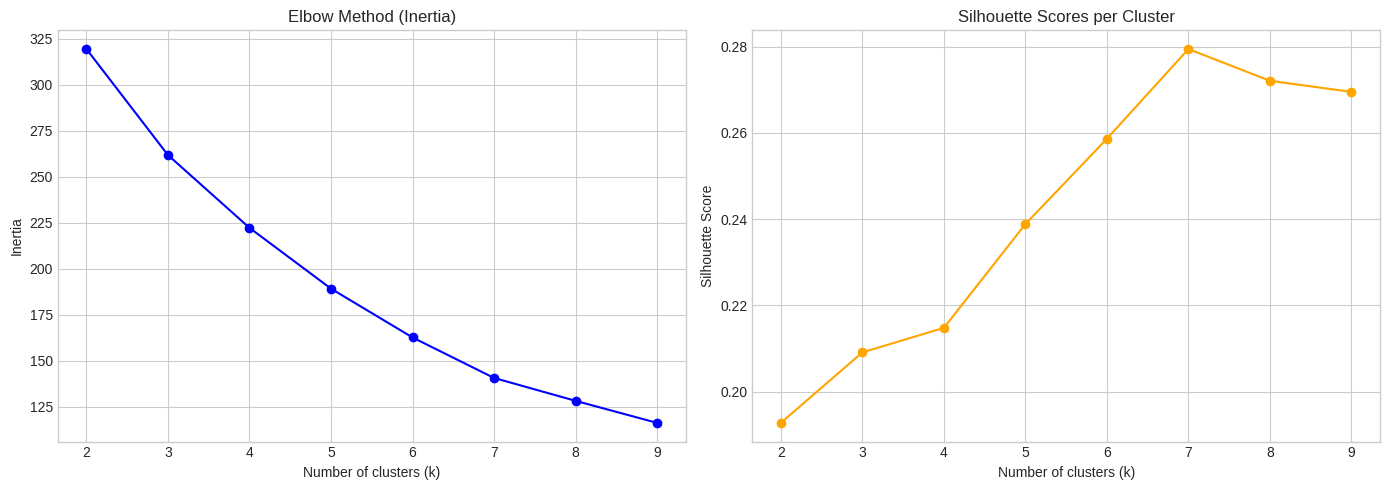

In [141]:
import matplotlib.pyplot as plt

if 'result' in globals():
    # Set a clean plot style
    plt.style.use("seaborn-v0_8-whitegrid")

    # Initialize subplots for Elbow Method (Inertia) and Silhouette Scores
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Inertia (Elbow Method)
    axes[0].plot(result.index, result['inertia'], marker='o', color='b')
    axes[0].set_title('Elbow Method (Inertia)')
    axes[0].set_xlabel('Number of clusters (k)')
    axes[0].set_ylabel('Inertia')

    # Plot Silhouette Scores
    axes[1].plot(result.index, result['silhouette'], marker='o', color='orange')
    axes[1].set_title('Silhouette Scores per Cluster')
    axes[1].set_xlabel('Number of clusters (k)')
    axes[1].set_ylabel('Silhouette Score')

    plt.tight_layout()
    plt.show()
else:
    print("[ERROR] The variable 'result' is not defined.")
    print("Please upload 'live.csv', run the data loading cell, and execute the clustering cell (gqX8Gk89w8W7) successfully first.")

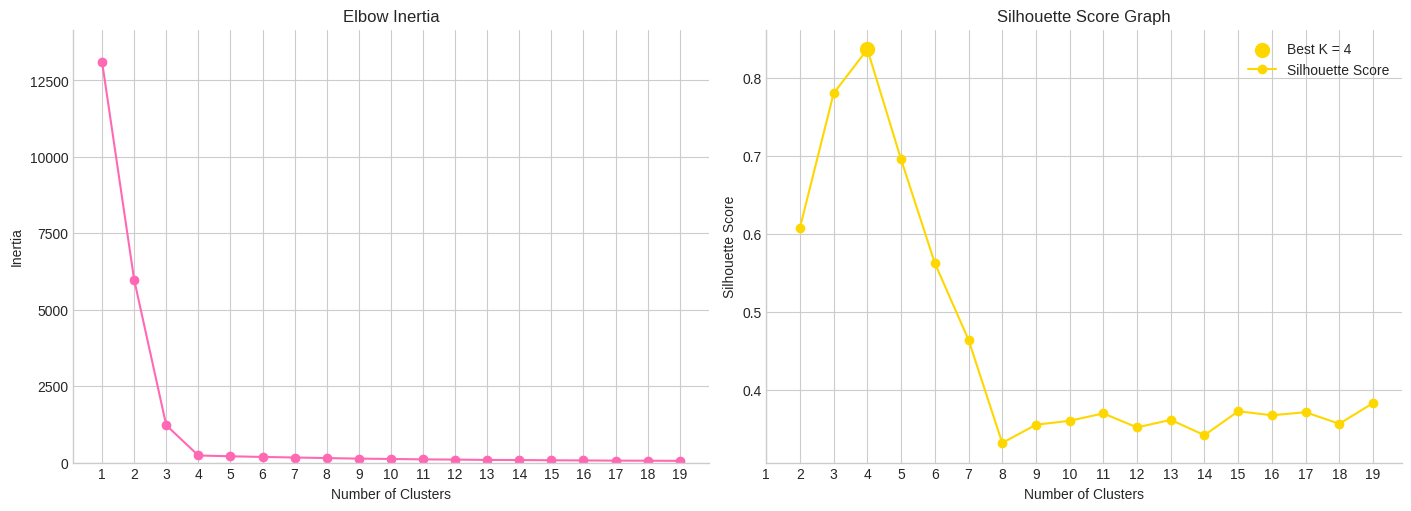

In [142]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

# 1. Sample dataset (replace this with your own scaled feature matrix X)
X, _ = make_blobs(n_samples=200, centers=4, cluster_std=0.8, random_state=42)

# 2. Compute inertia and silhouette scores for k = 1..19
k_range = range(1, 20)
records = []

for k in k_range:
  km = KMeans(n_clusters=k, n_init=10, random_state=42)
  labels = km.fit_predict(X)
  # Silhouette score requires at least 2 clusters
  sil_score = silhouette_score(X, labels) if k > 1 else np.nan
  records.append({"k": k, "inertia": km.inertia_, "silhouette": sil_score})

results = pd.DataFrame(records).set_index("k")
best_k = int(results["silhouette"].idxmax())
best_score = float(results.loc[best_k, "silhouette"])

# 3. Plot Elbow (Inertia) and Silhouette Score side-by-side
plt.style.use("seaborn-v0_8-whitegrid")

fig, axis = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")

# Elbow Inertia graph (k = 1..19)
axis[0].plot(results.index, results["inertia"], "o-", color="#FF69B4")
axis[0].set(title="Elbow Inertia", ylabel="Inertia")
axis[0].set_ylim(0, results["inertia"].max() * 1.08)
axis[0].yaxis.set_major_locator(MaxNLocator(nbins=7, integer=True))

# Silhouette Score graph (k = 2..19 since k = 1 has no silhouette score)
silhouette_val = results["silhouette"].dropna()
axis[1].scatter(
    best_k,
    best_score,
    color="#FFD700",
    s=100,
    zorder=3,
    label=f"Best K = {best_k}",
)
axis[1].plot(
    silhouette_val.index,
    silhouette_val.values,
    "o-",
    color="#FFD700",
    label="Silhouette Score",
)
axis[1].set(title="Silhouette Score Graph", ylabel="Silhouette Score")
axis[1].legend(loc="best")

for ax in axis:
  ax.set(xlabel="Number of Clusters", xticks=results.index)
  ax.spines[["top", "right"]].set_visible(False)

plt.show()